 İki özellik kullanarak Iris sınıflandırmasının karar bölgelerini görselleştirir.


In [1]:
# %% İki özellik kullanarak Iris sınıflandırmasının karar bölgelerini görselleştirir.
# Iris veri setini yükleme fonksiyonunu içe aktarır.
from sklearn.datasets import load_iris
# Karar ağacı sınıflandırıcısını içe aktarır.
from sklearn.tree import DecisionTreeClassifier
# Bir sınıflandırıcının karar bölgelerini çizmek için görselleştirme aracını içe aktarır.
from sklearn.inspection import DecisionBoundaryDisplay
# Grafik çizim arayüzünü içe aktarır.
import matplotlib.pyplot as plt
# Sayısal diziler ve koşullu indeksleme için NumPy'ı içe aktarır.
import numpy as np

In [2]:
# Uyarı mesajlarını yönetmek için standart warnings modülünü içe aktarır.
import warnings
# Bu örnek çalışırken uyarı mesajlarının gösterilmemesini sağlar.
warnings.filterwarnings("ignore")


In [3]:
# Iris veri setini bu görselleştirme örneği için yükler.
iris = load_iris()

In [4]:
# Veri setindeki farklı sınıfların sayısını hesaplar.
n_classes = len(iris.target_names)
# Sınıfları grafiklerde ayırt etmek için kullanılacak renkleri tanımlar.
plot_colors = "ryb"


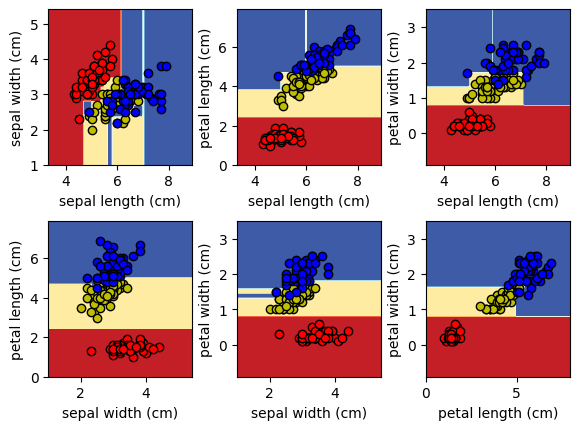

In [5]:
# Özellik indekslerinin altı olası ikilisini sırayla inceler.
for pairidx, pair in enumerate([[0,1], [0,2], [0,3], [1,2], [1,3], [2,3]]):
    # Seçilen iki özelliğin değerlerini bütün örnekler için alır.
    X = iris.data[:, pair]
    # Her örneğin gerçek sınıf etiketlerini alır.
    y = iris.target
    # Seçilen iki özellik kullanılarak yeni bir karar ağacını eğitir.
    clf = DecisionTreeClassifier().fit(X, y)
    # 2 satır ve 3 sütunluk düzen içinde bu özellik ikilisine ait paneli seçer.
    ax = plt.subplot(2, 3, pairidx + 1)
    # Alt grafiklerin aralıklarını ve kenar boşluklarını düzenler.
    plt.tight_layout(h_pad = 0.5, w_pad = 0.5, pad = 2.5)
    # Eğitilen ağacın karar bölgelerini seçilen özellik adlarıyla birlikte çizer.
    DecisionBoundaryDisplay.from_estimator(clf, 
                                           X,  # Karar bölgelerinin çizileceği iki boyutlu özellik verisi.
                                           cmap = plt.cm.RdYlBu,  # Karar bölgelerinde kullanılacak renk haritası.
                                           response_method="predict",  # Her noktayı tahmin edilen sınıfa göre renklendirir.
                                           ax=ax,  # Karar bölgelerini geçerli alt grafiğe çizer.
                                           xlabel=iris.feature_names[pair[0]],  # X eksenine ilk özelliğin adını yazar.
                                           ylabel=iris.feature_names[pair[1]])  # Y eksenine ikinci özelliğin adını yazar.

    # Her sınıfı ayrı renkle çizmek üzere sınıf numaralarıyla renkleri eşleştirir.
    for i, color in zip(range(n_classes), plot_colors):
        # Mevcut sınıfa ait örneklerin satır indekslerini bulur.
        idx = np.where(y == i)
        # Mevcut sınıfın örneklerini saçılım grafiği olarak panele ekler.
        plt.scatter(X[idx, 0], X[idx, 1], c=color, label = iris.target_names[i], 
                    cmap = plt.cm.RdYlBu,  # Nokta renklerini yukarıdaki renk haritasıyla ilişkilendirir.
                    edgecolors="black")  # Noktaların çevresini siyah çizerek görünürlüklerini artırır.


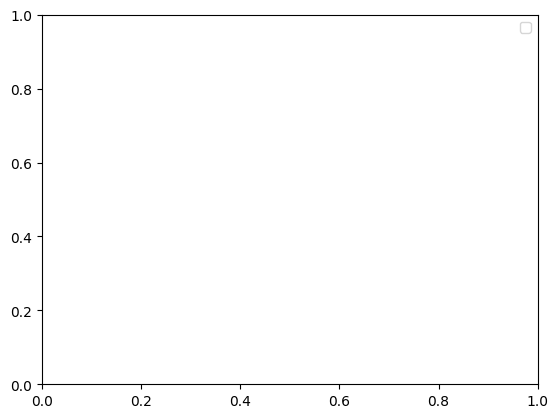

In [6]:
# Son çizilen alt grafik için sınıf adlarını içeren açıklama kutusunu gösterir.
plt.legend()


Diabetes veri setiyle karar ağacı regresyonunu eğitir ve hata ölçülerini hesaplar.


In [7]:
# Diabetes veri setini yükleme fonksiyonunu içe aktarır.
from sklearn.datasets import load_diabetes
# Veriyi eğitim ve test kümelerine ayırma fonksiyonunu içe aktarır.
from sklearn.model_selection import train_test_split
# Karar ağacı regresyon modelini içe aktarır.
from sklearn.tree import DecisionTreeRegressor
# Ortalama karesel hata ölçüsünü hesaplayan fonksiyonu içe aktarır.
from sklearn.metrics import mean_squared_error
# Karekök hesaplamak için NumPy'ı içe aktarır.
import numpy as np


In [8]:
# Diabetes regresyon veri setini yükler.
diabetes = load_diabetes()


In [9]:
# Modelin girdi özelliklerini veri setinden alır.
X = diabetes.data  # Özellikler (features).
# Tahmin edilmesi gereken sürekli hedef değerleri veri setinden alır.
y = diabetes.target  # Hedef değerler (target).


In [10]:
# Veriyi yüzde 80 eğitim ve yüzde 20 test kümelerine ayırır; rastgeleliği sabitler.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [11]:
# Tekrarlanabilir sonuçlar için rastgelelik tohumu belirlenmiş regresyon ağacını oluşturur.
tree_reg = DecisionTreeRegressor(random_state = 42)
# Regresyon ağacını eğitim verileri ve hedef değerleriyle eğitir.
tree_reg.fit(X_train, y_train)


DecisionTreeRegressor(random_state=42)

In [12]:
# Test özellikleri için sürekli hedef tahminlerini üretir.
y_pred = tree_reg.predict(X_test)


In [13]:
# Gerçek test hedefleri ile tahminler arasındaki ortalama karesel hatayı hesaplar.
mse = mean_squared_error(y_test, y_pred)
# Ortalama karesel hata değerini ekrana yazdırır.
print("mse: ",mse)


mse:  4976.797752808989


In [14]:
# Ortalama karesel hatanın karekökünü alarak RMSE değerini hesaplar.
rmse = np.sqrt(mse)
# Karekök ortalama karesel hata değerini ekrana yazdırır.
print("rmse: ",rmse)


rmse:  70.54642267903446


Sentetik veriye iki farklı derinlikte regresyon ağacı uydurup sonuçları çizer.


In [15]:
# Karar ağacı regresyon modelini içe aktarır.
from sklearn.tree import DecisionTreeRegressor
# Rastgele sayı üretimi, sıralama ve diziler için NumPy'ı içe aktarır.
import numpy as np
# Grafik çizimi için Matplotlib'i içe aktarır.
import matplotlib.pyplot as plt

In [16]:
# 0 ile 5 arasında 80 rastgele değer üretir, sıralar ve sütun biçiminde düzenler.
X = np.sort(5 * np.random.rand(80,1), axis = 0)
# Her X değerinin sinüsünü hesaplayıp hedef dizisini tek boyuta indirger.
y = np.sin(X).ravel()
# Her beşinci hedef değerine rastgele miktarda gürültü ekleyerek aykırı değerler oluşturur.
y[::5] += 5 * (0.5 - np.random.rand(16))


In [17]:
# Aşağıdaki satır etkinleştirilirse sentetik eğitim verisini saçılım grafiğinde gösterir.
# plt.scatter(X, y)

# Maksimum derinliği 2 olan karar ağacı regresyon modelini oluşturur.
regr_1 = DecisionTreeRegressor(max_depth=2)
# Maksimum derinliği 15 olan karar ağacı regresyon modelini oluşturur.
regr_2 = DecisionTreeRegressor(max_depth=15)
# Sığ ağacı sentetik özellik ve hedef verileriyle eğitir.
regr_1.fit(X, y)
# Daha derin ağacı aynı sentetik verilerle eğitir.
regr_2.fit(X, y)



DecisionTreeRegressor(max_depth=15)

In [18]:
# 0'dan 5'e kadar 0.05 aralıklarla test noktaları oluşturup sütun biçimine dönüştürür.
X_test = np.arange(0, 5, 0.05)[:, np.newaxis]
# Sığ ağacın test noktalarındaki tahminlerini hesaplar.
y_pred_1 = regr_1.predict(X_test)
# Derin ağacın test noktalarındaki tahminlerini hesaplar.
y_pred_2 = regr_2.predict(X_test)


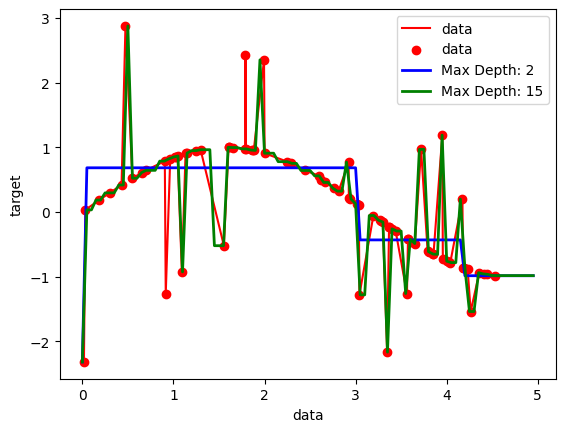

In [19]:
# Yeni bir grafik çizim alanı oluşturur.
plt.figure()
# Eğitim verilerini kırmızı çizgiyle gösterip açıklama etiketini ekler.
plt.plot(X, y, c = "red", label = "data")
# Eğitim örneklerini kırmızı noktalarla gösterip açıklama etiketini ekler.
plt.scatter(X, y, c = "red", label = "data")
# Sığ ağacın tahmin eğrisini mavi renkte ve 2 piksel çizgi kalınlığıyla çizer.
plt.plot(X_test, y_pred_1, color = "blue", label = "Max Depth: 2", linewidth = 2)
# Derin ağacın tahmin eğrisini yeşil renkte ve 2 piksel çizgi kalınlığıyla çizer.
plt.plot(X_test, y_pred_2, color = "green", label = "Max Depth: 15", linewidth = 2)
# Yatay eksene veri açıklaması ekler.
plt.xlabel("data")
# Dikey eksene hedef açıklaması ekler.
plt.ylabel("target")
# Veri ve iki model eğrisi için açıklama kutusunu gösterir.
plt.legend()


